In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Machine Learning libraries
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Mall_Customers.csv to Mall_Customers.csv


In [3]:
import io

file_name = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")

print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
# Dataset information

print("DATASET INFORMATION")
print("-" * 40)

df.info()

# Statistical summary
print("\nSTATISTICAL SUMMARY")

display(df.describe())

# Missing values
print("\nMISSING VALUES")

print(df.isnull().sum())

# Duplicate records
print("\nDUPLICATE RECORDS")

print("Duplicates:", df.duplicated().sum())

DATASET INFORMATION
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

STATISTICAL SUMMARY


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



MISSING VALUES
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

DUPLICATE RECORDS
Duplicates: 0


CUSTOMER GENDER DISTRIBUTION
Gender
Female    112
Male       88
Name: count, dtype: int64


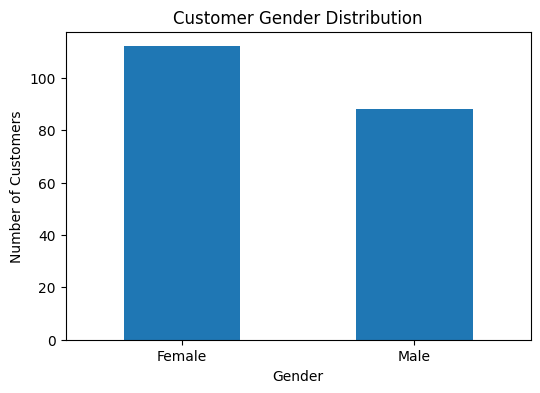

In [5]:
# Gender distribution

print("CUSTOMER GENDER DISTRIBUTION")
print(df["Gender"].value_counts())

plt.figure(figsize=(6, 4))

df["Gender"].value_counts().plot(
    kind="bar",
    title="Customer Gender Distribution"
)

plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

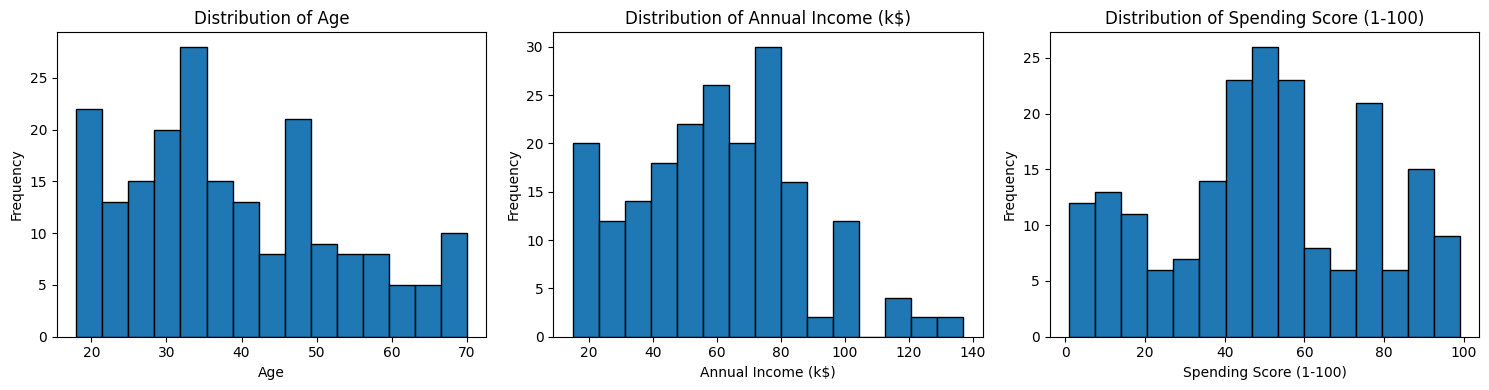

In [6]:
# Plot numerical feature distributions

features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

plt.figure(figsize=(15, 4))

for i, column in enumerate(features):
    plt.subplot(1, 3, i + 1)

    plt.hist(df[column], bins=15, edgecolor="black")

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

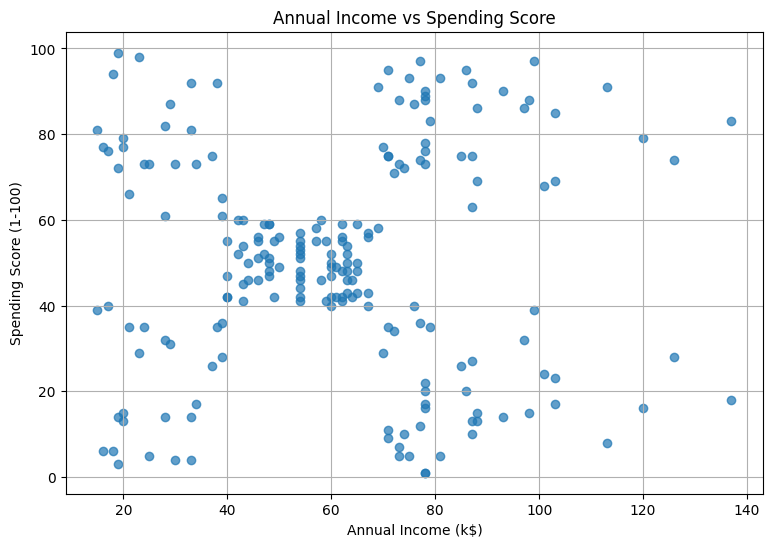

In [7]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    alpha=0.7
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")

plt.grid(True)
plt.show()

CORRELATION MATRIX


,Age,Annual Income (k$),Spending Score (1-100)
Age,1.000000,-0.012398,-0.327227
Annual Income (k$),-0.012398,1.000000,0.009903
Spending Score (1-100),-0.327227,0.009903,1.000000


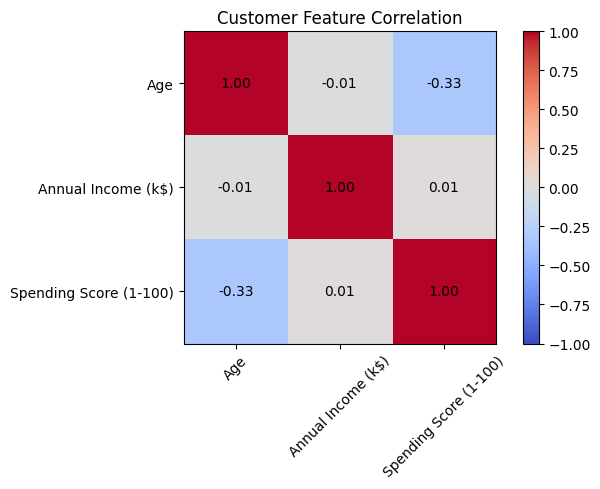

In [8]:
# Calculate correlation

correlation = df[
    ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
].corr()

print("CORRELATION MATRIX")
display(correlation)

# Visualize correlation

plt.figure(figsize=(7, 5))

plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar()

plt.xticks(range(len(correlation.columns)),
           correlation.columns, rotation=45)

plt.yticks(range(len(correlation.columns)),
           correlation.columns)

plt.title("Customer Feature Correlation")

for i in range(len(correlation)):
    for j in range(len(correlation)):
        plt.text(j, i, f"{correlation.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.tight_layout()
plt.show()

In [9]:
# Select features for customer segmentation

X = df[
    [
        'Annual Income (k$)',
        'Spending Score (1-100)'
    ]
].copy()

print("Selected features:")
display(X.head())

print("\nDataset shape:", X.shape)

Selected features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Dataset shape: (200, 2)


In [10]:
from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Transform features
X_scaled = scaler.fit_transform(X)

# Convert scaled data into DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

print("Feature scaling completed!")

display(X_scaled_df.head())

print("\nScaled feature means:")
print(X_scaled_df.mean())

print("\nScaled feature standard deviations:")
print(X_scaled_df.std())

Feature scaling completed!


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Scaled feature means:
Annual Income (k$)       -2.131628e-16
Spending Score (1-100)   -1.465494e-16
dtype: float64

Scaled feature standard deviations:
Annual Income (k$)        1.002509
Spending Score (1-100)    1.002509
dtype: float64


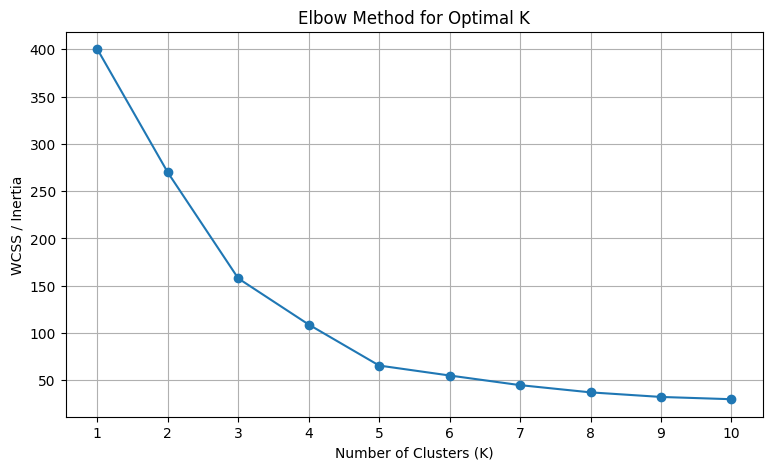

In [11]:
from sklearn.cluster import KMeans

wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

# Plot Elbow Method
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS / Inertia')

plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

In [12]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.3213
K = 3, Silhouette Score = 0.4666
K = 4, Silhouette Score = 0.4939
K = 5, Silhouette Score = 0.5547
K = 6, Silhouette Score = 0.5399
K = 7, Silhouette Score = 0.5281
K = 8, Silhouette Score = 0.4552
K = 9, Silhouette Score = 0.4571
K = 10, Silhouette Score = 0.4432


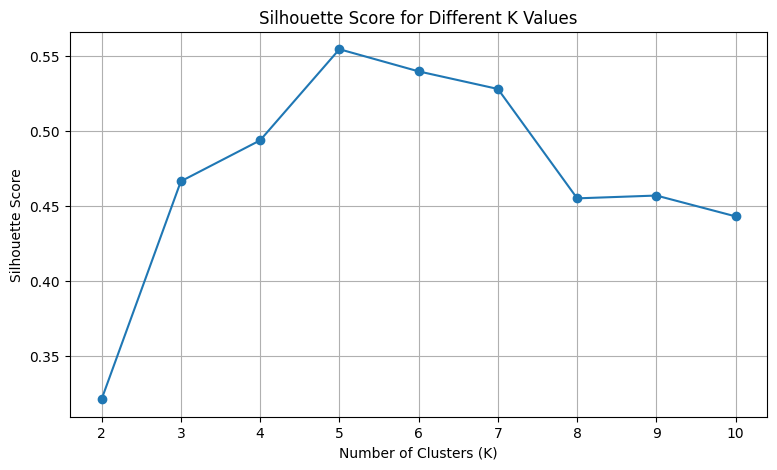

In [13]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.title('Silhouette Score for Different K Values')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [14]:
# Initialize K-Means with 5 clusters

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Train model and assign cluster labels
cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to original dataset
df['Cluster'] = cluster_labels

print("K-Means clustering completed!")

print("\nCluster distribution:")
print(df['Cluster'].value_counts().sort_index())

display(df.head(10))

K-Means clustering completed!

Cluster distribution:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


In [15]:
# Get cluster centres in scaled form
centers_scaled = kmeans.cluster_centers_

# Convert centres back to original scale
centers_original = scaler.inverse_transform(
    centers_scaled
)

centers_df = pd.DataFrame(
    centers_original,
    columns=X.columns
)

centers_df.index.name = 'Cluster'

print("CUSTOMER CLUSTER CENTRES")

display(centers_df.round(2))

CUSTOMER CLUSTER CENTRES


,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


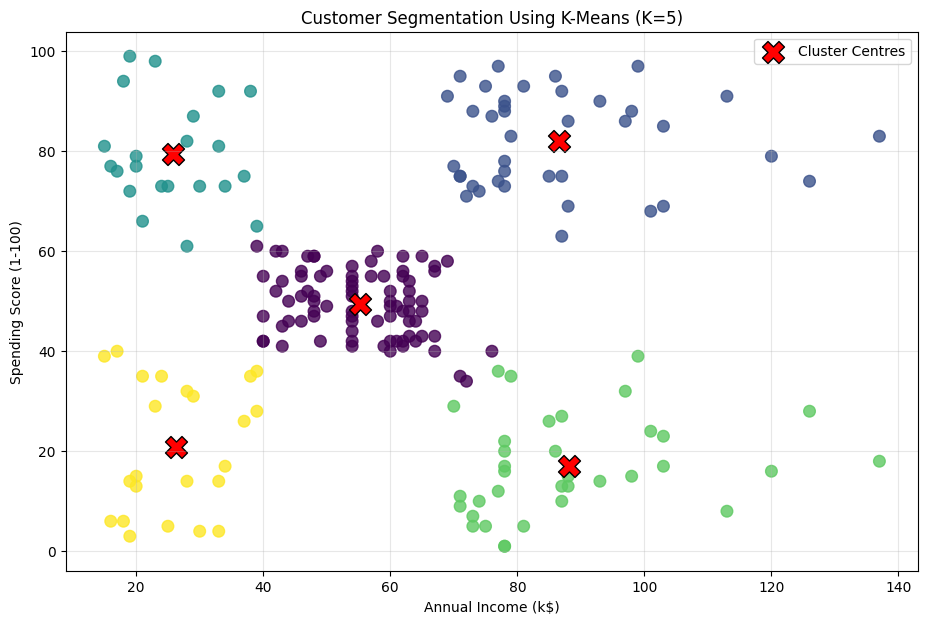

In [16]:
plt.figure(figsize=(11, 7))

plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['Cluster'],
    cmap='viridis',
    s=70,
    alpha=0.8
)

# Plot cluster centres
plt.scatter(
    centers_df['Annual Income (k$)'],
    centers_df['Spending Score (1-100)'],
    c='red',
    marker='X',
    s=250,
    edgecolors='black',
    label='Cluster Centres'
)

plt.title('Customer Segmentation Using K-Means (K=5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [17]:
# Analyze each cluster

cluster_analysis = df.groupby('Cluster').agg({
    'CustomerID': 'count',
    'Age': 'mean',
    'Annual Income (k$)': 'mean',
    'Spending Score (1-100)': 'mean'
})

cluster_analysis = cluster_analysis.rename(
    columns={
        'CustomerID': 'Number_of_Customers',
        'Age': 'Average_Age',
        'Annual Income (k$)': 'Average_Income',
        'Spending Score (1-100)': 'Average_Spending_Score'
    }
)

print("CUSTOMER SEGMENT ANALYSIS")

display(cluster_analysis.round(2))

CUSTOMER SEGMENT ANALYSIS


,Number_of_Customers,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


In [18]:
from sklearn.metrics import silhouette_score

final_silhouette = silhouette_score(
    X_scaled,
    df['Cluster']
)

print("FINAL K-MEANS EVALUATION")
print("-" * 40)

print("Number of clusters:", kmeans.n_clusters)
print("Number of customers:", len(df))
print(f"Silhouette Score: {final_silhouette:.4f}")
print("Inertia:", round(kmeans.inertia_, 4))

FINAL K-MEANS EVALUATION
----------------------------------------
Number of clusters: 5
Number of customers: 200
Silhouette Score: 0.5547
Inertia: 65.5684


In [19]:
cluster_percentages = (
    df['Cluster']
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("CUSTOMER SEGMENT PERCENTAGES")

display(
    cluster_percentages.round(2).rename(
        'Percentage'
    ).to_frame()
)

CUSTOMER SEGMENT PERCENTAGES


,Percentage
Cluster,
0,40.5
1,19.5
2,11.0
3,17.5
4,11.5


In [20]:
# Save customer segmentation results

df.to_csv(
    'Customer_Segmentation_Results.csv',
    index=False
)

print("Customer segmentation results saved!")

Customer segmentation results saved!


In [21]:
cluster_percentages = (
    df['Cluster']
    .value_counts(normalize=True)
    .sort_index() * 100
)

display(
    cluster_percentages.round(2).rename(
        'Percentage'
    ).to_frame()
)

,Percentage
Cluster,
0,40.5
1,19.5
2,11.0
3,17.5
4,11.5


In [22]:
df.to_csv(
    'Customer_Segmentation_Results.csv',
    index=False
)

print("Customer segmentation results saved!")

Customer segmentation results saved!
